# CP2/CP3 — Assistente de atendimento de e-commerce com SmolLM2-360M, RAG e LoRA

**Disciplina:** Generative AI for Engineering — Prof. Dr. Francisco Elânio
**Turma:** 4ESR-2026

| Integrante | RM |
|---|---|
| Rodrigo Paixão Silveira | 96869 |
| _(nome)_ | _(RM)_ |
| _(nome)_ | _(RM)_ |
| _(nome)_ | _(RM)_ |

## Problema escolhido

Uma loja virtual fictícia recebe chamados de clientes escritos em português sobre 20 assuntos (entrega, defeito, troca, reembolso, cancelamento, pagamento, fraude, nota fiscal, garantia, acesso à conta, privacidade, vale-presente e outros). O objetivo é treinar **localmente, em GPU,** uma LLM pequena para:

1. receber o chamado do cliente;
2. consultar a base de políticas da loja (**RAG**);
3. classificar **categoria** e **prioridade** e indicar a **equipe** responsável;
4. devolver um **JSON** com o procedimento e a **fonte** (documento) usada;
5. responder `sem_informacao` quando a base não cobre a pergunta, em vez de inventar.

| Componente | Escolha |
|---|---|
| LLM | [`HuggingFaceTB/SmolLM2-360M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct) |
| Embeddings (RAG) | [`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2) |
| Fine-tuning | LoRA (PEFT) — só um adaptador pequeno é treinado |
| Frontend | Streamlit (`app_streamlit.py`), publicado no Streamlit Community Cloud |

> **Ideia central:** o fine-tuning ensina **como responder** (formato JSON, rótulos válidos, recusar quando não sabe); o RAG fornece **o conhecimento** usado na resposta.

### Melhorias em relação ao notebook da Aula 9

- **Limiar do RAG escolhido por experimento** (seção 6), em vez de fixo em 0,55.
- **Valores permitidos no system prompt**, para o modelo não inventar rótulos (como "moderada").
- **Treino com documento distrator**: parte dos exemplos traz 2 documentos no contexto (o certo e um errado), como acontece na busca real com `top_k=2`.
- **Exemplos negativos com documento irrelevante** no contexto, ensinando a responder `sem_informacao` mesmo quando a busca traz algo.
- **Validação separada por frase** (a mesma frase nunca aparece no treino e na validação).
- **Vários experimentos de hiperparâmetros** comparados automaticamente (seção 11).

### Versão 2 — o que mudou depois da primeira rodada

Na **versão 1** o melhor experimento (C: r=16, 5 épocas) subiu a pontuação de **13,8% para 48,2%**, mas a análise caso a caso (resultados em `saidas/`) mostrou dois problemas:

| Problema observado na v1 | Evidência | Correção na v2 |
|---|---|---|
| A busca não achava o documento certo | 3 dos 8 chamados de teste com documento ficaram com contexto vazio (Recall@2 = 75% no melhor limiar) | **Exemplos indexados**: o RAG compara o chamado com o texto do documento **e** com perguntas típicas de cada documento |
| Categoria, prioridade e equipe eram "chutadas" | Quando o documento vinha, a **fonte** estava certa em 5 de 5 casos, mas a equipe era sempre `financeiro` e a prioridade quase sempre errada — esses campos **não estavam no contexto**, o modelo precisava decorá-los | O contexto passa a trazer **categoria, prioridade, equipe e procedimento** de cada documento: o modelo só precisa **copiar do documento certo** |
| `fonte` com texto em vez de `null` | Em chamados fora da base, o modelo escrevia "Nenhum documento..." no campo `fonte` | **Validação da saída**: `fonte` que não é um ID existente vira `null` |

Na v2 a base também passou de **8 para 20 documentos** (e de 12 para 25 casos de teste), ficando em arquivos separados (`base_conhecimento.py` e `chamados_exemplo.py`). Por isso a comparação v1 × v2 não é exata: a v2 resolve um problema maior.

Os resultados da v2 são salvos em `saidas_v2/`; os da v1 continuam em `saidas/`.

## 1. Preparação do ambiente (VSCode + GPU)

Este notebook roda **localmente no VSCode, com GPU NVIDIA**, dentro de um ambiente virtual (`.venv`) criado só para o trabalho. As instalações são feitas **no terminal (PowerShell)**, na pasta do projeto:

```powershell
py -3.12 -m venv .venv
.venv\Scripts\Activate.ps1

# pasta temporária e cache do pip fora do C: (o PyTorch com CUDA tem mais de 2,5 GB)
$env:TMP = "D:\pip-temp"; $env:TEMP = "D:\pip-temp"; $env:PIP_CACHE_DIR = "D:\pip-cache"

# 1º o PyTorch com CUDA (troque cu128 pela versão do nvidia-smi: veja pytorch.org/get-started/locally)
python -m pip install torch --index-url https://download.pytorch.org/whl/cu128

# 2º as demais bibliotecas
python -m pip install "transformers==4.46.3" "datasets==3.1.0" "peft==0.13.2" "accelerate==1.1.1" "sentence-transformers==3.3.1" scikit-learn matplotlib pandas streamlit ipykernel ipywidgets

# conferência: deve mostrar +cu128 True
python -c "import torch; print(torch.__version__, torch.cuda.is_available())"
```

Depois, no VSCode, escolha o kernel **Select Kernel → Python Environments → .venv**.

Para o print da GPU, instale as extensões do VSCode **GPU Environment** e **GPU Monitor**.

## 2. Importações, semente e dispositivo

As primeiras linhas desligam o TensorFlow e guardam os modelos do Hugging Face na pasta `hf-cache` do projeto. A semente fixa (42) deixa o experimento reprodutível. O código usa GPU (`cuda`) quando disponível. Em GPUs com suporte a `bfloat16` (série RTX 30xx/40xx em diante), ele é usado por ser mais estável no treino; nas demais, `float16`.

In [1]:
import os
from pathlib import Path

# Antes de importar o transformers:
# - USE_TF=0 evita que um TensorFlow instalado na máquina quebre a importação;
# - HF_HOME guarda os modelos baixados na pasta do projeto (fora do disco C:).
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"
os.environ.setdefault("HF_HOME", str(Path.cwd() / "hf-cache"))

import gc
import json
import random
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import f1_score
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    default_data_collator,
)

SEED = 42


def fixar_semente(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


fixar_semente()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USAR_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
USAR_FP16 = DEVICE == "cuda" and not USAR_BF16
DTYPE = torch.bfloat16 if USAR_BF16 else (torch.float16 if USAR_FP16 else torch.float32)

PASTA_SAIDA = Path("saidas_v2")
PASTA_SAIDA.mkdir(exist_ok=True)

print("Dispositivo:", DEVICE)
print("Precisão:", DTYPE)
if DEVICE != "cuda":
    print("\nATENÇÃO: GPU não encontrada. O trabalho exige GPU — confira a instalação do PyTorch com CUDA.")

Dispositivo: cuda
Precisão: torch.bfloat16


## 3. Informações da GPU (print para a entrega)

Tire o print desta saída **e** do painel das extensões GPU Environment / GPU Monitor durante o treino (seção 11).

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA usada pelo PyTorch:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    propriedades = torch.cuda.get_device_properties(0)
    print("GPU:", propriedades.name)
    print(f"Memória total: {propriedades.total_memory / 1024**3:.1f} GB")
    print(f"Compute capability: {propriedades.major}.{propriedades.minor}")
    print("Suporta bfloat16:", torch.cuda.is_bf16_supported())

try:
    print("\n" + subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("\nnvidia-smi não encontrado no PATH.")

PyTorch: 2.14.1+cu126
CUDA usada pelo PyTorch: 12.6
CUDA disponível: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Memória total: 6.0 GB
Compute capability: 8.6
Suporta bfloat16: True

Wed Oct 14 21:34:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.74                 Driver Version: 591.74         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   59C    P0             14W /   95W | 

## 4. Configurações gerais

In [3]:
MODEL_NAME = "HuggingFaceTB/SmolLM2-360M-Instruct"
EMBEDDING_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

MAX_LENGTH = 768       # tokens por exemplo de treino; recalculado na seção 10 pelo maior exemplo
MAX_NEW_TOKENS = 160   # tokens gerados na resposta
TOP_K = 2              # documentos recuperados pelo RAG

# Lote do treino. Se faltar memória na GPU, use LOTE = 2 e ACUMULACAO = 8.
LOTE = 4
ACUMULACAO = 4

PRIORIDADES = ["baixa", "media", "alta", "critica"]
STATUS = ["respondido", "sem_informacao"]

## 5. Base de conhecimento e chamados de exemplo

Os dados ficam em **dois arquivos separados**, na mesma pasta do notebook, para facilitar a edição sem mexer no código:

| Arquivo | Conteúdo |
|---|---|
| `base_conhecimento.py` | os 20 documentos com as políticas de uma **loja virtual fictícia** e as mensagens padrão |
| `chamados_exemplo.py` | frases de treino, perguntas fora da base, casos de teste e casos de demonstração |

Cada documento tem:

- `conteudo`: o texto que o RAG busca e entrega ao modelo;
- `categoria`, `prioridade`, `equipe`, `procedimento`: o gabarito que o modelo aprende a devolver no JSON;
- `resposta_automatica`: a mensagem enviada ao **cliente** quando o modelo indica aquele documento como fonte.

> O modelo **não** escreve a mensagem ao cliente: ele classifica o chamado e aponta a `fonte`; o sistema então envia a `resposta_automatica` do documento apontado. Assim o cliente sempre recebe um texto revisado pela empresa, e o modelo não tem como inventar prazos ou políticas na conversa.

In [4]:
import importlib

import base_conhecimento as modulo_base
import chamados_exemplo as modulo_chamados

# reload: se os arquivos forem editados, basta rodar esta célula de novo
importlib.reload(modulo_base)
importlib.reload(modulo_chamados)

from base_conhecimento import RESPOSTA_ENCAMINHAMENTO, RESPOSTA_FORA_DA_BASE, base_conhecimento
from chamados_exemplo import casos_demonstracao, casos_teste, chamados_sem_base, modelos_chamados

documentos_por_id = {doc["id"]: doc for doc in base_conhecimento}

# As categorias permitidas vêm da própria base (mais "fora_da_base" para chamados sem resposta).
CATEGORIAS = sorted({doc["categoria"] for doc in base_conhecimento}) + ["fora_da_base"]

campos = ["id", "titulo", "categoria", "prioridade", "equipe", "procedimento", "resposta_automatica"]
faltando = [(doc.get("id"), c) for doc in base_conhecimento for c in campos if not doc.get(c)]
assert not faltando, f"Campos faltando na base: {faltando}"
assert set(modelos_chamados) == set(documentos_por_id), "Cada documento precisa de frases em modelos_chamados."

frases_treino = {f for frases in modelos_chamados.values() for f in frases} | set(chamados_sem_base)
assert not [c for c in casos_teste if c["chamado"] in frases_treino], "Caso de teste repetido no treino!"

print("Documentos:", len(base_conhecimento))
print("Frases por documento:", {k: len(v) for k, v in modelos_chamados.items()})
print("Perguntas fora da base:", len(chamados_sem_base))
print("Casos de teste inéditos:", len(casos_teste))
print("Categorias:", ", ".join(CATEGORIAS))

pd.DataFrame(base_conhecimento)[["id", "titulo", "categoria", "prioridade", "equipe"]]

Documentos: 20
Frases por documento: {'DOC-001': 5, 'DOC-002': 5, 'DOC-003': 5, 'DOC-004': 5, 'DOC-005': 5, 'DOC-006': 5, 'DOC-007': 5, 'DOC-008': 5, 'DOC-009': 5, 'DOC-010': 5, 'DOC-011': 5, 'DOC-012': 5, 'DOC-013': 5, 'DOC-014': 5, 'DOC-015': 5, 'DOC-016': 5, 'DOC-017': 5, 'DOC-018': 5, 'DOC-019': 5, 'DOC-020': 5}
Perguntas fora da base: 14
Casos de teste inéditos: 25
Categorias: cancelamento, conta, cupom, defeito, endereco, entrega, estoque, fidelidade, fraude, frete, garantia, nota_fiscal, pagamento, parcelamento, pedido_incorreto, privacidade, reembolso, site_app, troca, vale_presente, fora_da_base


,id,titulo,categoria,prioridade,equipe
0,DOC-001,Atraso na entrega,entrega,media,logistica
1,DOC-002,Produto com defeito ou danificado,defeito,alta,trocas_devolucoes
2,DOC-003,"Troca por arrependimento, tamanho ou cor",troca,baixa,trocas_devolucoes
3,DOC-004,Prazo de reembolso,reembolso,media,financeiro
4,DOC-005,Cancelamento de pedido,cancelamento,media,atendimento
5,DOC-006,Pagamento recusado,pagamento,alta,financeiro
6,DOC-007,Cupom de desconto inválido,cupom,baixa,marketing
7,DOC-008,Compra não reconhecida ou suspeita de fraude,fraude,critica,seguranca
8,DOC-009,Alteração do endereço de entrega,endereco,media,logistica
9,DOC-010,Valor do frete e frete grátis,frete,baixa,atendimento


## 6. RAG: busca por significado

O modelo de embeddings transforma textos em vetores. A **similaridade de cosseno** mede o quanto o chamado se parece com cada documento. Só entram no contexto os documentos com nota **acima do limiar** (`LIMIAR_RAG`), no máximo `TOP_K`.

**Exemplos indexados (v2):** cada documento é representado pelo seu texto **e** por 4 perguntas típicas de clientes (as frases de treino). A nota do documento é a **maior** similaridade entre o chamado e qualquer um desses textos. Isso aproxima a linguagem do cliente ("veio trincada") da linguagem da política ("produto danificado"). A 5ª frase de cada documento **não** é indexada: ela é usada para escolher o limiar sem vazamento.

**Contexto com metadados (v2):** além do texto, cada documento entregue ao modelo traz categoria, prioridade, equipe e procedimento.

- Limiar **baixo** → traz documentos que não têm nada a ver;
- Limiar **alto** → deixa de trazer o documento certo (problema da Aula 9: Recall@2 de 37,5% com 0,55).

In [5]:
def formatar_contexto(documentos):
    if not documentos:
        return "Nenhum documento relevante foi encontrado na base."
    return "\n\n".join(
        f"[{doc['id']}] {doc['titulo']}\n"
        f"{doc['conteudo']}\n"
        f"Categoria: {doc['categoria']} | Prioridade: {doc['prioridade']} | Equipe: {doc['equipe']}\n"
        f"Procedimento: {doc['procedimento']}"
        for doc in documentos
    )

In [6]:
modelo_embedding = SentenceTransformer(EMBEDDING_NAME, device=DEVICE)

# Índice: texto de cada documento + 4 perguntas típicas (a 5ª fica de fora para validar o limiar).
textos_indice, documento_do_texto = [], []
for posicao, doc in enumerate(base_conhecimento):
    textos_indice.append(f"{doc['titulo']}. {doc['conteudo']}")
    documento_do_texto.append(posicao)
    for frase in modelos_chamados[doc["id"]][:-1]:
        textos_indice.append(frase)
        documento_do_texto.append(posicao)

embeddings_indice = modelo_embedding.encode(textos_indice, normalize_embeddings=True, convert_to_tensor=True)
documento_do_texto = np.array(documento_do_texto)
print(f"Índice do RAG: {len(textos_indice)} textos para {len(base_conhecimento)} documentos")

LIMIAR_RAG = 0.50  # valor inicial; é ajustado no experimento logo abaixo


def buscar_documentos(pergunta, top_k=TOP_K, limiar=None):
    """Retorna até top_k documentos com similaridade >= limiar.

    A nota de cada documento é a maior similaridade entre o chamado e os textos daquele documento no índice.
    """
    limiar = LIMIAR_RAG if limiar is None else limiar
    embedding = modelo_embedding.encode(pergunta, normalize_embeddings=True, convert_to_tensor=True)
    similaridades = util.cos_sim(embedding, embeddings_indice)[0].float().cpu().numpy()
    notas = np.array([similaridades[documento_do_texto == i].max() for i in range(len(base_conhecimento))])
    ordem = np.argsort(-notas)[:top_k]
    return [
        {**base_conhecimento[i], "score": float(notas[i])}
        for i in ordem
        if notas[i] >= limiar
    ]


for frase in ["Meu pedido não chegou ainda", "Vocês vendem geladeira usada?"]:
    print(frase, "→", [(d["id"], round(d["score"], 3)) for d in buscar_documentos(frase, limiar=0.0)])

Índice do RAG: 100 textos para 20 documentos
Meu pedido não chegou ainda → [('DOC-001', 0.857), ('DOC-005', 0.772)]
Vocês vendem geladeira usada? → [('DOC-007', 0.4), ('DOC-018', 0.397)]


### Experimento 1 — escolha do limiar do RAG

O limiar é escolhido com a **5ª frase de cada documento** (que não está no índice) e as perguntas fora da base, cada uma com as 3 aberturas — sem usar o conjunto de teste. Para cada limiar medimos:

- **Recall@K**: o documento certo veio entre os recuperados?
- **Rejeição correta**: em perguntas fora da base, nenhum documento passou do limiar?

O limiar escolhido é o que tem a **maior média das duas métricas**.

,limiar,recall@k,rejeicao_correta,media
0,0.350000,63.3%,28.6%,46.0%
1,0.400000,63.3%,35.7%,49.5%
2,0.450000,63.3%,64.3%,63.8%
3,0.500000,58.3%,83.3%,70.8%
4,0.550000,53.3%,90.5%,71.9%
5,0.600000,41.7%,97.6%,69.6%
6,0.650000,30.0%,100.0%,65.0%
7,0.700000,15.0%,100.0%,57.5%


Limiar escolhido: 0.55


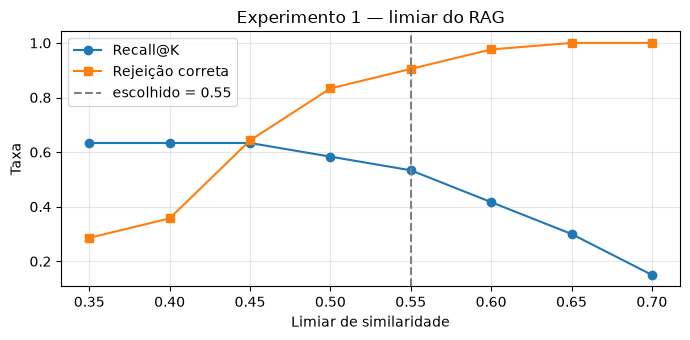

In [7]:
aberturas_busca = ["", "Olá, preciso de ajuda. ", "Chamado do usuário: "]
casos_busca = [(a + frases[-1], doc_id) for doc_id, frases in modelos_chamados.items() for a in aberturas_busca]
casos_busca += [(a + frase, None) for frase in chamados_sem_base for a in aberturas_busca]


def avaliar_busca(casos, limiar, top_k=TOP_K):
    recall, rejeicao = [], []
    for texto, doc_esperado in casos:
        ids = [d["id"] for d in buscar_documentos(texto, top_k=top_k, limiar=limiar)]
        if doc_esperado is None:
            rejeicao.append(len(ids) == 0)
        else:
            recall.append(doc_esperado in ids)
    return float(np.mean(recall)), float(np.mean(rejeicao))


linhas = []
for limiar in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    recall, rejeicao = avaliar_busca(casos_busca, limiar)
    linhas.append({"limiar": limiar, "recall@k": recall, "rejeicao_correta": rejeicao, "media": (recall + rejeicao) / 2})

df_limiar = pd.DataFrame(linhas)
melhor = df_limiar.sort_values(["media", "limiar"], ascending=[False, False]).iloc[0]
LIMIAR_RAG = float(melhor["limiar"])
df_limiar.to_csv(PASTA_SAIDA / "experimento_limiar_rag.csv", index=False)

display(df_limiar.style.format({"recall@k": "{:.1%}", "rejeicao_correta": "{:.1%}", "media": "{:.1%}"}))
print("Limiar escolhido:", LIMIAR_RAG)

plt.figure(figsize=(7, 3.5))
plt.plot(df_limiar["limiar"], df_limiar["recall@k"], marker="o", label="Recall@K")
plt.plot(df_limiar["limiar"], df_limiar["rejeicao_correta"], marker="s", label="Rejeição correta")
plt.axvline(LIMIAR_RAG, color="gray", linestyle="--", label=f"escolhido = {LIMIAR_RAG}")
plt.xlabel("Limiar de similaridade")
plt.ylabel("Taxa")
plt.title("Experimento 1 — limiar do RAG")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "experimento_limiar_rag.png", dpi=120)
plt.show()

## 7. Modelo, prompt e geração

O `SYSTEM_PROMPT` lista os **valores permitidos** de categoria, prioridade e status. As funções:

- `montar_prompt`: regras (system) + CONTEXTO + CHAMADO no formato de chat do modelo;
- `gerar_texto`: geração sem sorteio (`do_sample=False`), sempre a resposta mais provável;
- `extrair_json`: pega do primeiro `{` ao último `}`; se não for JSON válido, devolve `None`;
- `validar_saida` (v2): se a `fonte` não for um ID da base (ex.: o modelo escreveu um texto), ela vira `null`;
- `resposta_ao_cliente`: devolve a `resposta_automatica` do documento apontado na `fonte` (ou a mensagem de encaminhamento a um atendente);
- `responder`: junta tudo, com um interruptor para ligar/desligar o RAG.

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"  # necessário para mascarar o prompt corretamente no treino


def carregar_modelo_base():
    modelo = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE, low_cpu_mem_usage=True)
    modelo.config.pad_token_id = tokenizer.pad_token_id
    return modelo.to(DEVICE)


def limpar_gpu():
    """Libera a memória da GPU depois de apagar (del) os modelos."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


SYSTEM_PROMPT = f"""Você é um assistente de atendimento de uma loja virtual.
Use somente as informações presentes no contexto.
Não invente políticas, prazos ou procedimentos.
Se o contexto não for suficiente ou não tratar do chamado, use status "sem_informacao".
Valores permitidos:
- categoria: {', '.join(CATEGORIAS)}
- prioridade: baixa, media, alta, critica
- status: respondido, sem_informacao
Retorne somente um JSON válido, sem Markdown e sem explicações adicionais,
com as chaves: categoria, prioridade, equipe, procedimento, fonte e status."""


def montar_prompt(chamado, contexto):
    mensagens = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"CONTEXTO:\n{contexto}\n\nCHAMADO:\n{chamado}"},
    ]
    return tokenizer.apply_chat_template(mensagens, tokenize=False, add_generation_prompt=True)


def gerar_texto(modelo, prompt, max_new_tokens=MAX_NEW_TOKENS):
    modelo.eval()
    entradas = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    with torch.no_grad():
        saida = modelo.generate(
            **entradas,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    novos = saida[0, entradas["input_ids"].shape[1]:]
    return tokenizer.decode(novos, skip_special_tokens=True).strip()


def extrair_json(texto):
    try:
        objeto = json.loads(texto[texto.index("{"): texto.rindex("}") + 1])
        return objeto if isinstance(objeto, dict) else None
    except (ValueError, json.JSONDecodeError):
        return None


def validar_saida(objeto):
    """Regra de negócio: a fonte só pode ser o ID de um documento da base; senão vira null."""
    if objeto is not None and objeto.get("fonte") not in documentos_por_id:
        objeto["fonte"] = None
    return objeto


def resposta_ao_cliente(objeto):
    """Escolhe a mensagem enviada ao cliente a partir do JSON do modelo."""
    if objeto is None:
        return RESPOSTA_ENCAMINHAMENTO
    if objeto.get("status") == "sem_informacao":
        return RESPOSTA_FORA_DA_BASE
    documento = documentos_por_id.get(objeto.get("fonte"))
    return documento["resposta_automatica"] if documento else RESPOSTA_ENCAMINHAMENTO


def responder(modelo, chamado, usar_rag=True, top_k=TOP_K):
    inicio = time.perf_counter()
    documentos = buscar_documentos(chamado, top_k=top_k) if usar_rag else []
    texto = gerar_texto(modelo, montar_prompt(chamado, formatar_contexto(documentos)))
    objeto = validar_saida(extrair_json(texto))
    return {
        "texto": texto,
        "json": objeto,
        "resposta_cliente": resposta_ao_cliente(objeto),
        "documentos": [d["id"] for d in documentos],
        "scores": [round(d["score"], 3) for d in documentos],
        "tempo_s": time.perf_counter() - inicio,
    }

### Função de avaliação

Aplicada a todos os modelos com os mesmos casos de teste inéditos (1 por documento + 5 fora da base):

| Métrica | O que mede |
|---|---|
| JSON válido | a resposta é um JSON que o sistema consegue ler |
| Acurácia da categoria | categoria igual à do gabarito |
| F1 macro da prioridade | acerto de prioridade, equilibrando as 4 classes |
| Acurácia da fonte | citou o documento certo (ou nenhum, quando fora da base) |
| Acurácia do status | `respondido` × `sem_informacao` |
| Fonte fundamentada | a fonte citada estava entre os documentos que o RAG trouxe |
| **Pontuação** | média de categoria, prioridade, fonte e status — usada para escolher o melhor experimento |

In [9]:
def avaliar_sistema(modelo, usar_rag=True, casos=None):
    casos = casos if casos is not None else casos_teste
    linhas = []
    for numero, caso in enumerate(casos, start=1):
        saida = responder(modelo, caso["chamado"], usar_rag=usar_rag)
        objeto = saida["json"]
        valido = objeto is not None

        def campo(chave):
            return objeto.get(chave) if valido else "__json_invalido__"

        fonte_prevista = campo("fonte")
        fundamentada = (fonte_prevista in saida["documentos"]) if fonte_prevista else len(saida["documentos"]) == 0

        linhas.append({
            "caso": numero,
            "chamado": caso["chamado"],
            "docs_recuperados": saida["documentos"],
            "json_valido": valido,
            "categoria_real": caso["categoria"],
            "categoria_prevista": campo("categoria"),
            "prioridade_real": caso["prioridade"],
            "prioridade_prevista": campo("prioridade"),
            "fonte_real": caso["doc"],
            "fonte_prevista": fonte_prevista,
            "status_real": caso["status"],
            "status_previsto": campo("status"),
            "fonte_fundamentada": fundamentada,
            "tempo_s": saida["tempo_s"],
            "texto": saida["texto"],
            "resposta_cliente": saida["resposta_cliente"],
        })

    df = pd.DataFrame(linhas)

    def acuracia(real, previsto):
        return float((df[real].fillna("SEM_FONTE").astype(str) == df[previsto].fillna("SEM_FONTE").astype(str)).mean())

    metricas = {
        "json_valido": float(df["json_valido"].mean()),
        "categoria": acuracia("categoria_real", "categoria_prevista"),
        "prioridade_f1": float(f1_score(
            df["prioridade_real"].astype(str), df["prioridade_prevista"].astype(str),
            labels=PRIORIDADES, average="macro", zero_division=0,
        )),
        "fonte": acuracia("fonte_real", "fonte_prevista"),
        "status": acuracia("status_real", "status_previsto"),
        "fonte_fundamentada": float(df["fonte_fundamentada"].mean()),
        "tempo_medio_s": float(df["tempo_s"].mean()),
    }
    metricas["pontuacao"] = float(np.mean([metricas[k] for k in ["categoria", "prioridade_f1", "fonte", "status"]]))
    return metricas, df


FORMATO_METRICAS = {
    k: "{:.1%}" for k in ["json_valido", "categoria", "prioridade_f1", "fonte", "status", "fonte_fundamentada", "pontuacao"]
}
FORMATO_METRICAS["tempo_medio_s"] = "{:.2f}"

## 8. O "antes": modelo original, sem fine-tuning

Avaliamos o modelo original nas mesmas condições do sistema final (com RAG), para comparar antes × depois.

In [10]:
modelo = carregar_modelo_base()
total_parametros = sum(p.numel() for p in modelo.parameters())
print(f"Parâmetros do modelo: {total_parametros:,} (~{total_parametros / 1e6:.1f} milhões)")

respostas_antes = {}
for caso in casos_demonstracao:
    saida = responder(modelo, caso["chamado"], usar_rag=True)
    respostas_antes[caso["nome"]] = saida["texto"]
    print("=" * 90)
    print(caso["nome"], "| documentos:", saida["documentos"])
    print(saida["texto"])

metricas_base, df_base = avaliar_sistema(modelo, usar_rag=True)
resultados = [{"experimento": "0_modelo_original", "rag": True, **metricas_base}]

del modelo
limpar_gpu()

display(pd.DataFrame(resultados).style.format(FORMATO_METRICAS))

Parâmetros do modelo: 361,821,120 (~361.8 milhões)
Entrega atrasada | documentos: ['DOC-001', 'DOC-005']
{
  "categoria": "entrega",
  "prioridade": "media",
  "equipe": "logistica",
  "procedimento": "Verificar o rastreamento em Meus Pedidos; após 5 dias úteis de atraso, solicitar reenvio ou reembolso.",
  "fonte": "Meus Pedidos",
  "status": "respondido"
}
Compra suspeita | documentos: ['DOC-008', 'DOC-006']
{
  "categoria": "fraude",
  "prioridade": "critica",
  "equipe": "seguranca",
  "procedimento": "trocar a senha imediatamente e encaminhar à Seguranca para bloquear os pedidos suspeitos",
  "fonte": "Cliente deve trocar a senha imediatamente e o caso é encaminhado à Equipe de Seguranca que bloqueia os pedidos suspeitos"
}
Informação ausente | documentos: ['DOC-010']
"Vocês têm loja física no Rio de Janeiro."


,experimento,rag,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,tempo_medio_s,pontuacao
0,0_modelo_original,True,76.0%,36.0%,46.0%,8.0%,32.0%,36.0%,7.07,30.5%


## 9. Conjunto de fine-tuning

O conjunto é sintético. Cada frase é combinada com 3 aberturas ("", "Olá, preciso de ajuda.", "Chamado do usuário:"), e cada abertura usa um **contexto diferente**:

| Abertura | Chamado da base | Chamado fora da base |
|---|---|---|
| 1ª | só o documento certo | contexto vazio |
| 2ª | documento certo + distrator | contexto vazio |
| 3ª | distrator + documento certo | 1 documento **irrelevante** |

Assim o modelo pratica **escolher** o documento certo entre dois e **recusar** quando o documento recuperado não tem relação com o chamado.

**Validação separada por frase:** a última frase de cada documento e as 2 últimas perguntas fora da base vão só para a validação.

In [11]:
aberturas = ["", "Olá, preciso de ajuda. ", "Chamado do usuário: "]
rng = random.Random(SEED)


def resposta_documento(doc):
    return json.dumps({
        "categoria": doc["categoria"],
        "prioridade": doc["prioridade"],
        "equipe": doc["equipe"],
        "procedimento": doc["procedimento"],
        "fonte": doc["id"],
        "status": "respondido",
    }, ensure_ascii=False)


RESPOSTA_SEM_BASE = json.dumps({
    "categoria": "fora_da_base",
    "prioridade": "baixa",
    "equipe": None,
    "procedimento": None,
    "fonte": None,
    "status": "sem_informacao",
}, ensure_ascii=False)


def documento_aleatorio(exceto=None):
    return rng.choice([d for d in base_conhecimento if d["id"] != exceto])


exemplos_treino, exemplos_validacao = [], []

for doc_id, frases in modelos_chamados.items():
    doc = documentos_por_id[doc_id]
    for i, frase in enumerate(frases):
        destino = exemplos_validacao if i == len(frases) - 1 else exemplos_treino
        for j, abertura in enumerate(aberturas):
            if j == 0:
                documentos = [doc]
            else:
                distrator = documento_aleatorio(exceto=doc_id)
                documentos = [doc, distrator] if j == 1 else [distrator, doc]
            destino.append({
                "chamado": abertura + frase,
                "contexto": formatar_contexto(documentos),
                "resposta": resposta_documento(doc),
                "classe": doc_id,
            })

for i, frase in enumerate(chamados_sem_base):
    destino = exemplos_validacao if i >= len(chamados_sem_base) - 2 else exemplos_treino
    for j, abertura in enumerate(aberturas):
        documentos = [documento_aleatorio()] if j == 2 else []
        destino.append({
            "chamado": abertura + frase,
            "contexto": formatar_contexto(documentos),
            "resposta": RESPOSTA_SEM_BASE,
            "classe": "SEM_BASE",
        })

rng.shuffle(exemplos_treino)
rng.shuffle(exemplos_validacao)

print("Treino:", len(exemplos_treino), "| Validação:", len(exemplos_validacao))
display(pd.DataFrame(exemplos_treino)["classe"].value_counts().sort_index().to_frame("treino"))

Treino: 276 | Validação: 66


,treino
classe,
DOC-001,12
DOC-002,12
DOC-003,12
DOC-004,12
DOC-005,12
DOC-006,12
DOC-007,12
DOC-008,12
DOC-009,12


## 10. Tokenização

Os tokens do prompt (regras + contexto + chamado) e do preenchimento recebem rótulo `-100`: o modelo **só é cobrado pela resposta JSON**, não por repetir o prompt.

In [12]:
def tokenizar_exemplo(exemplo):
    prompt = montar_prompt(exemplo["chamado"], exemplo["contexto"])
    tokens = tokenizer(
        prompt + exemplo["resposta"] + tokenizer.eos_token,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length",
    )
    tamanho_prompt = len(tokenizer(prompt, add_special_tokens=False)["input_ids"])
    tokens["labels"] = [
        -100 if (i < tamanho_prompt or mascara == 0) else token
        for i, (token, mascara) in enumerate(zip(tokens["input_ids"], tokens["attention_mask"]))
    ]
    return tokens


# Mede o maior exemplo (prompt + resposta) para nenhum ser cortado.
maior = max(
    len(tokenizer(montar_prompt(ex["chamado"], ex["contexto"]) + ex["resposta"] + tokenizer.eos_token,
                  add_special_tokens=False)["input_ids"])
    for ex in exemplos_treino + exemplos_validacao
)
# Ajusta MAX_LENGTH ao maior exemplo (múltiplo de 32): nada é cortado e não sobra preenchimento à toa.
MAX_LENGTH = int(np.ceil(maior / 32) * 32)
print(f"Maior exemplo: {maior} tokens → MAX_LENGTH = {MAX_LENGTH}")

colunas = list(exemplos_treino[0].keys())
treino_tokenizado = Dataset.from_list(exemplos_treino).map(tokenizar_exemplo, remove_columns=colunas)
validacao_tokenizada = Dataset.from_list(exemplos_validacao).map(tokenizar_exemplo, remove_columns=colunas)

print("Treino:", len(treino_tokenizado), "| Validação:", len(validacao_tokenizada))

Maior exemplo: 780 tokens → MAX_LENGTH = 800


Map:   0%|          | 0/276 [00:00<?, ? examples/s]

Map:   0%|          | 0/66 [00:00<?, ? examples/s]

Treino: 276 | Validação: 66


## 11. Experimento 2 — fine-tuning com LoRA e diferentes parâmetros

O LoRA congela os ~362 milhões de pesos originais e treina só matrizes pequenas (rank `r`) nas camadas de atenção e MLP. Cada experimento:

1. recarrega o modelo **original** (para os experimentos não se misturarem);
2. aplica o LoRA com os parâmetros da linha;
3. treina, guardando o melhor checkpoint pela loss de validação;
4. avalia nos casos de teste inéditos **com** e **sem** RAG;
5. salva o adaptador em `saidas/adaptadores/<nome>`.

| Exp. | O que varia | Pergunta que responde |
|---|---|---|
| A | configuração da Aula 9 | ponto de partida |
| B | rank menor (r=8) | um adaptador menor perde qualidade? |
| C | mais épocas (5) | treinar mais ajuda ou sobreajusta? |
| D | learning rate menor (5e-5) | passos menores aprendem o suficiente? |
| E | 8 épocas | na v1 a loss ainda caía com 5 épocas: treinar mais continua ajudando? |

> Tire o print das extensões **GPU Monitor / GPU Environment** enquanto esta célula estiver rodando.
>
> **Tempo:** com 20 documentos o treino tem cerca de 260 exemplos, e os 5 experimentos (treino + avaliação) devem levar perto de **1 hora**. Para rodar mais rápido, apague linhas da lista `EXPERIMENTOS` (por exemplo, deixe só A, C e E).

In [13]:
EXPERIMENTOS = [
    {"nome": "A_aula_r16_ep3_lr2e-4", "r": 16, "alpha": 32, "epocas": 3, "lr": 2e-4},
    {"nome": "B_r8_ep3_lr2e-4", "r": 8, "alpha": 16, "epocas": 3, "lr": 2e-4},
    {"nome": "C_r16_ep5_lr2e-4", "r": 16, "alpha": 32, "epocas": 5, "lr": 2e-4},
    {"nome": "D_r16_ep3_lr5e-5", "r": 16, "alpha": 32, "epocas": 3, "lr": 5e-5},
    {"nome": "E_r16_ep8_lr2e-4", "r": 16, "alpha": 32, "epocas": 8, "lr": 2e-4},
]

MODULOS_LORA = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
historicos = {}


def treinar_experimento(cfg):
    fixar_semente()
    modelo = get_peft_model(carregar_modelo_base(), LoraConfig(
        r=cfg["r"],
        lora_alpha=cfg["alpha"],
        lora_dropout=0.05,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
        target_modules=MODULOS_LORA,
    ))
    modelo.config.use_cache = False
    modelo.enable_input_require_grads()
    modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    treinaveis, total = modelo.get_nb_trainable_parameters()

    argumentos = TrainingArguments(
        output_dir=str(PASTA_SAIDA / "checkpoints" / cfg["nome"]),
        num_train_epochs=cfg["epocas"],
        per_device_train_batch_size=LOTE,
        per_device_eval_batch_size=LOTE,
        gradient_accumulation_steps=ACUMULACAO,
        learning_rate=cfg["lr"],
        warmup_steps=10,
        weight_decay=0.01,
        logging_steps=2,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=1,
        fp16=USAR_FP16,
        bf16=USAR_BF16,
        report_to="none",
        seed=SEED,
        remove_unused_columns=False,
        optim="adamw_torch",
    )
    trainer = Trainer(
        model=modelo,
        args=argumentos,
        train_dataset=treino_tokenizado,
        eval_dataset=validacao_tokenizada,
        data_collator=default_data_collator,
    )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    inicio = time.perf_counter()
    trainer.train()
    tempo_treino = time.perf_counter() - inicio
    memoria_gb = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0

    historico = pd.DataFrame(trainer.state.log_history)
    historicos[cfg["nome"]] = historico

    modelo.config.use_cache = True
    metricas_rag, df_rag = avaliar_sistema(modelo, usar_rag=True)
    metricas_sem_rag, _ = avaliar_sistema(modelo, usar_rag=False)

    pasta = PASTA_SAIDA / "adaptadores" / cfg["nome"]
    modelo.save_pretrained(pasta)
    tokenizer.save_pretrained(pasta)
    df_rag.to_csv(PASTA_SAIDA / f"avaliacao_{cfg['nome']}.csv", index=False)

    info = {
        "r": cfg["r"], "alpha": cfg["alpha"], "epocas": cfg["epocas"], "lr": cfg["lr"],
        "params_treinaveis": treinaveis, "pct_treinavel": treinaveis / total,
        "loss_treino_final": float(historico["loss"].dropna().iloc[-1]),
        "loss_validacao_melhor": float(historico["eval_loss"].dropna().min()),
        "tempo_treino_s": tempo_treino, "memoria_pico_gb": memoria_gb,
    }
    del trainer, modelo
    limpar_gpu()
    return [
        {"experimento": cfg["nome"], "rag": True, **info, **metricas_rag},
        {"experimento": cfg["nome"], "rag": False, **info, **metricas_sem_rag},
    ]


for cfg in EXPERIMENTOS:
    print("\n" + "#" * 90 + f"\nEXPERIMENTO {cfg['nome']}\n" + "#" * 90)
    resultados.extend(treinar_experimento(cfg))
    pd.DataFrame(resultados).to_csv(PASTA_SAIDA / "resultados_experimentos.csv", index=False)

print("\nTodos os experimentos concluídos.")


##########################################################################################
EXPERIMENTO A_aula_r16_ep3_lr2e-4
##########################################################################################


  0%|          | 0/51 [00:00<?, ?it/s]

{'loss': 0.2804, 'grad_norm': 0.3451320230960846, 'learning_rate': 4e-05, 'epoch': 0.12}
{'loss': 0.2564, 'grad_norm': 0.36263489723205566, 'learning_rate': 8e-05, 'epoch': 0.23}
{'loss': 0.231, 'grad_norm': 0.3577316701412201, 'learning_rate': 0.00012, 'epoch': 0.35}
{'loss': 0.248, 'grad_norm': 0.2937336266040802, 'learning_rate': 0.00016, 'epoch': 0.46}
{'loss': 0.1375, 'grad_norm': 0.20947585999965668, 'learning_rate': 0.0002, 'epoch': 0.58}
{'loss': 0.1181, 'grad_norm': 0.20625633001327515, 'learning_rate': 0.0001902439024390244, 'epoch': 0.7}
{'loss': 0.0953, 'grad_norm': 0.17140357196331024, 'learning_rate': 0.0001804878048780488, 'epoch': 0.81}
{'loss': 0.0925, 'grad_norm': 0.15352287888526917, 'learning_rate': 0.0001707317073170732, 'epoch': 0.93}


  0%|          | 0/17 [00:00<?, ?it/s]

{'eval_loss': 0.0439499132335186, 'eval_runtime': 7.8075, 'eval_samples_per_second': 8.453, 'eval_steps_per_second': 2.177, 'epoch': 0.99}
{'loss': 0.0381, 'grad_norm': 0.12894675135612488, 'learning_rate': 0.00016097560975609758, 'epoch': 1.04}
{'loss': 0.0456, 'grad_norm': 0.10134817659854889, 'learning_rate': 0.00015121951219512197, 'epoch': 1.16}
{'loss': 0.0307, 'grad_norm': 0.0893579050898552, 'learning_rate': 0.00014146341463414634, 'epoch': 1.28}
{'loss': 0.0203, 'grad_norm': 0.11760801821947098, 'learning_rate': 0.00013170731707317076, 'epoch': 1.39}
{'loss': 0.0293, 'grad_norm': 0.07936357706785202, 'learning_rate': 0.00012195121951219512, 'epoch': 1.51}
{'loss': 0.0293, 'grad_norm': 0.07977943122386932, 'learning_rate': 0.00011219512195121953, 'epoch': 1.62}
{'loss': 0.0213, 'grad_norm': 0.08673924952745438, 'learning_rate': 0.0001024390243902439, 'epoch': 1.74}
{'loss': 0.0148, 'grad_norm': 0.07593570649623871, 'learning_rate': 9.26829268292683e-05, 'epoch': 1.86}
{'loss': 

...

{'eval_loss': 0.0021428342442959547, 'eval_runtime': 7.8167, 'eval_samples_per_second': 8.443, 'eval_steps_per_second': 2.175, 'epoch': 5.97}
{'loss': 0.0009, 'grad_norm': 0.005783206317573786, 'learning_rate': 5.0793650793650794e-05, 'epoch': 6.03}
{'loss': 0.0006, 'grad_norm': 0.003234793432056904, 'learning_rate': 4.761904761904762e-05, 'epoch': 6.14}
{'loss': 0.0007, 'grad_norm': 0.00222654826939106, 'learning_rate': 4.4444444444444447e-05, 'epoch': 6.26}
{'loss': 0.0007, 'grad_norm': 0.00562310079112649, 'learning_rate': 4.126984126984127e-05, 'epoch': 6.38}
{'loss': 0.0006, 'grad_norm': 0.0038596931844949722, 'learning_rate': 3.809523809523809e-05, 'epoch': 6.49}
{'loss': 0.0009, 'grad_norm': 0.0031870813108980656, 'learning_rate': 3.492063492063492e-05, 'epoch': 6.61}
{'loss': 0.0011, 'grad_norm': 0.018533820286393166, 'learning_rate': 3.1746031746031745e-05, 'epoch': 6.72}
{'loss': 0.0006, 'grad_norm': 0.0025045014917850494, 'learning_rate': 2.857142857142857e-05, 'epoch': 6.84

  0%|          | 0/17 [00:00<?, ?it/s]

{'eval_loss': 0.0019650182221084833, 'eval_runtime': 7.8266, 'eval_samples_per_second': 8.433, 'eval_steps_per_second': 2.172, 'epoch': 6.96}
{'loss': 0.0009, 'grad_norm': 0.008302832022309303, 'learning_rate': 2.2222222222222223e-05, 'epoch': 7.07}
{'loss': 0.0007, 'grad_norm': 0.0044408864341676235, 'learning_rate': 1.9047619047619046e-05, 'epoch': 7.19}
{'loss': 0.0008, 'grad_norm': 0.01096096821129322, 'learning_rate': 1.5873015873015872e-05, 'epoch': 7.3}
{'loss': 0.0007, 'grad_norm': 0.005499641411006451, 'learning_rate': 1.2698412698412699e-05, 'epoch': 7.42}
{'loss': 0.0006, 'grad_norm': 0.0018088740762323141, 'learning_rate': 9.523809523809523e-06, 'epoch': 7.54}
{'loss': 0.0007, 'grad_norm': 0.003215959295630455, 'learning_rate': 6.349206349206349e-06, 'epoch': 7.65}
{'loss': 0.0006, 'grad_norm': 0.0034852740354835987, 'learning_rate': 3.1746031746031746e-06, 'epoch': 7.77}
{'loss': 0.0007, 'grad_norm': 0.0024248084519058466, 'learning_rate': 0.0, 'epoch': 7.88}


  0%|          | 0/17 [00:00<?, ?it/s]

{'eval_loss': 0.002042098669335246, 'eval_runtime': 8.2499, 'eval_samples_per_second': 8.0, 'eval_steps_per_second': 2.061, 'epoch': 7.88}
{'train_runtime': 1082.2431, 'train_samples_per_second': 2.04, 'train_steps_per_second': 0.126, 'train_loss': 0.026434937739395536, 'epoch': 7.88}

Todos os experimentos concluídos.


## 12. Comparação dos experimentos

,experimento,rag,r,epocas,lr,loss_treino_final,loss_validacao_melhor,tempo_treino_s,memoria_pico_gb,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,pontuacao
0,0_modelo_original,True,—,—,—,—,—,—,—,76.0%,36.0%,46.0%,8.0%,32.0%,36.0%,30.5%
1,A_aula_r16_ep3_lr2e-4,True,16.000000,3.000000,2e-04,0.009,0.008,415,3.55,100.0%,48.0%,48.6%,52.0%,60.0%,96.0%,52.1%
2,A_aula_r16_ep3_lr2e-4,False,16.000000,3.000000,2e-04,0.009,0.008,415,3.55,100.0%,20.0%,17.1%,20.0%,20.0%,100.0%,19.3%
3,B_r8_ep3_lr2e-4,True,8.000000,3.000000,2e-04,0.019,0.017,401,3.47,100.0%,48.0%,49.2%,52.0%,64.0%,100.0%,53.3%
4,B_r8_ep3_lr2e-4,False,8.000000,3.000000,2e-04,0.019,0.017,401,3.47,100.0%,16.0%,17.1%,20.0%,24.0%,100.0%,19.3%
5,C_r16_ep5_lr2e-4,True,16.000000,5.000000,2e-04,0.003,0.003,691,3.55,100.0%,52.0%,49.2%,52.0%,64.0%,100.0%,54.3%
6,C_r16_ep5_lr2e-4,False,16.000000,5.000000,2e-04,0.003,0.003,691,3.55,100.0%,20.0%,17.1%,20.0%,20.0%,100.0%,19.3%
7,D_r16_ep3_lr5e-5,True,16.000000,3.000000,5e-05,0.076,0.074,382,3.55,92.0%,32.0%,46.7%,36.0%,72.0%,76.0%,46.7%
8,D_r16_ep3_lr5e-5,False,16.000000,3.000000,5e-05,0.076,0.074,382,3.55,92.0%,0.0%,16.7%,20.0%,68.0%,92.0%,26.2%
9,E_r16_ep8_lr2e-4,True,16.000000,8.000000,2e-04,0.001,0.002,1082,3.55,100.0%,52.0%,49.2%,52.0%,64.0%,100.0%,54.3%


Melhor experimento (pontuação com RAG): C_r16_ep5_lr2e-4


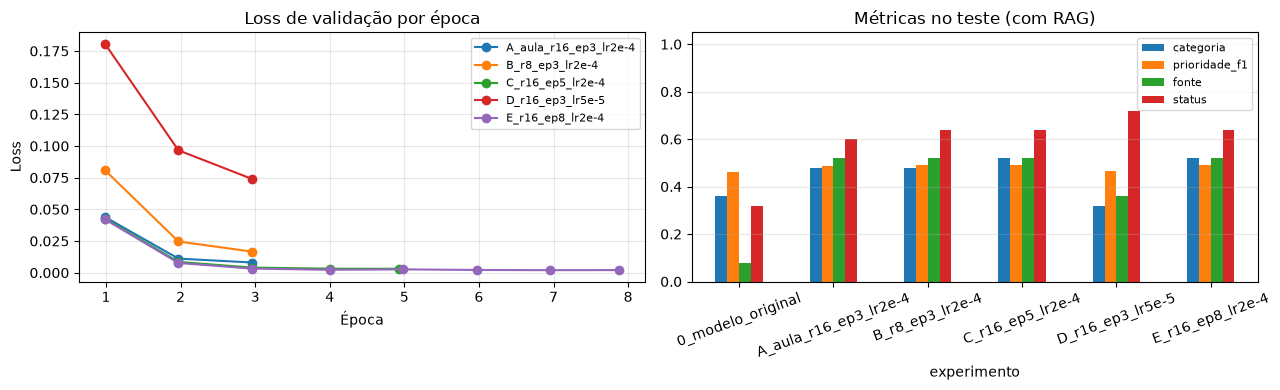

In [14]:
df_resultados = pd.DataFrame(resultados)
colunas_tabela = [
    "experimento", "rag", "r", "epocas", "lr", "loss_treino_final", "loss_validacao_melhor",
    "tempo_treino_s", "memoria_pico_gb", "json_valido", "categoria", "prioridade_f1",
    "fonte", "status", "fonte_fundamentada", "pontuacao",
]
display(
    df_resultados.reindex(columns=colunas_tabela)
    .style.format({**FORMATO_METRICAS, "loss_treino_final": "{:.3f}", "loss_validacao_melhor": "{:.3f}",
                   "tempo_treino_s": "{:.0f}", "memoria_pico_gb": "{:.2f}", "lr": "{:.0e}"}, na_rep="—")
)

com_rag = df_resultados[(df_resultados["rag"]) & (df_resultados["experimento"] != "0_modelo_original")]
MELHOR_EXPERIMENTO = com_rag.sort_values("pontuacao", ascending=False).iloc[0]["experimento"]
print("Melhor experimento (pontuação com RAG):", MELHOR_EXPERIMENTO)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for nome, historico in historicos.items():
    validacao = historico.dropna(subset=["eval_loss"])
    eixos[0].plot(validacao["epoch"], validacao["eval_loss"], marker="o", label=nome)
eixos[0].set_title("Loss de validação por época")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Loss")
eixos[0].grid(alpha=0.3)
eixos[0].legend(fontsize=8)

grafico = df_resultados[df_resultados["rag"]].set_index("experimento")[["categoria", "prioridade_f1", "fonte", "status"]]
grafico.plot(kind="bar", ax=eixos[1], rot=20)
eixos[1].set_title("Métricas no teste (com RAG)")
eixos[1].set_ylim(0, 1.05)
eixos[1].grid(alpha=0.3, axis="y")
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "comparacao_experimentos.png", dpi=120)
plt.show()

### Curva de aprendizado do melhor experimento

Treino e validação caindo juntos = aprendizado. Treino caindo e validação **subindo** = sobreajuste (decoreba).

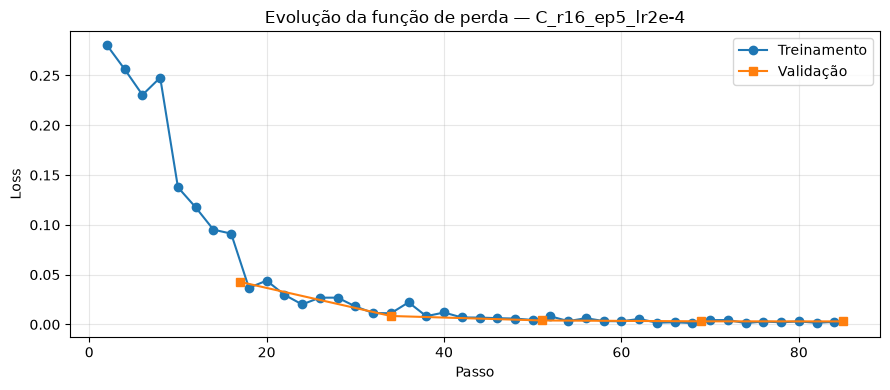

In [15]:
historico = historicos[MELHOR_EXPERIMENTO]
plt.figure(figsize=(9, 4))
dados_treino = historico.dropna(subset=["loss"])
dados_validacao = historico.dropna(subset=["eval_loss"])
plt.plot(dados_treino["step"], dados_treino["loss"], marker="o", label="Treinamento")
plt.plot(dados_validacao["step"], dados_validacao["eval_loss"], marker="s", label="Validação")
plt.xlabel("Passo")
plt.ylabel("Loss")
plt.title(f"Evolução da função de perda — {MELHOR_EXPERIMENTO}")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "curva_melhor_experimento.png", dpi=120)
plt.show()

## 13. Modelo final: antes × depois

Carregamos o modelo original + o adaptador LoRA do melhor experimento e comparamos as respostas dos 3 casos de demonstração.

In [16]:
PASTA_ADAPTADOR = PASTA_SAIDA / "adaptadores" / MELHOR_EXPERIMENTO

modelo_final = PeftModel.from_pretrained(carregar_modelo_base(), str(PASTA_ADAPTADOR)).to(DEVICE)
modelo_final.eval()
modelo_final.config.use_cache = True

for caso in casos_demonstracao:
    depois = responder(modelo_final, caso["chamado"], usar_rag=True)
    print("\n" + "=" * 90)
    print("CASO:", caso["nome"])
    print("CHAMADO:", caso["chamado"])
    print("\nANTES (modelo original + RAG):")
    print(respostas_antes[caso["nome"]])
    print(f"\nDEPOIS ({MELHOR_EXPERIMENTO} + RAG) | documentos: {depois['documentos']} scores: {depois['scores']}")
    print(depois["texto"])
    print("\nRESPOSTA DO ASSISTENTE AO CLIENTE:")
    print(depois["resposta_cliente"])


CASO: Entrega atrasada
CHAMADO: Meu pedido deveria ter chegado semana passada e até agora nada.

ANTES (modelo original + RAG):
{
  "categoria": "entrega",
  "prioridade": "media",
  "equipe": "logistica",
  "procedimento": "Verificar o rastreamento em Meus Pedidos; após 5 dias úteis de atraso, solicitar reenvio ou reembolso.",
  "fonte": "Meus Pedidos",
  "status": "respondido"
}

DEPOIS (C_r16_ep5_lr2e-4 + RAG) | documentos: ['DOC-001', 'DOC-005'] scores: [0.678, 0.589]
{"categoria": "cancelamento", "prioridade": "media", "equipe": "logistica", "procedimento": "Verificar o rastreamento em Meus Pedidos; após 5 dias úteis de atraso, solicitar reenvio ou reembolso.", "fonte": "DOC-001", "status": "respondido"}

RESPOSTA DO ASSISTENTE AO CLIENTE:
Olá! Sentimos muito pelo atraso. Você pode acompanhar a entrega pelo código de rastreamento em Meus Pedidos. Se o atraso passar de 5 dias úteis, é só solicitar o reenvio do produto ou o reembolso por lá. Se precisar de mais ajuda, estamos à dis

### Avaliação detalhada do modelo final

Resposta por resposta nos casos inéditos — útil para discutir os erros no README.

In [17]:
metricas_final, df_final = avaliar_sistema(modelo_final, usar_rag=True)

comparacao = pd.DataFrame([
    {"modelo": "Original + RAG (antes)", **metricas_base},
    {"modelo": f"{MELHOR_EXPERIMENTO} + RAG (depois)", **metricas_final},
]).set_index("modelo")
display(comparacao.style.format(FORMATO_METRICAS))

display(df_final[[
    "caso", "chamado", "docs_recuperados", "categoria_real", "categoria_prevista",
    "prioridade_real", "prioridade_prevista", "fonte_real", "fonte_prevista",
    "status_real", "status_previsto",
]])

,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,tempo_medio_s,pontuacao
modelo,,,,,,,,
Original + RAG (antes),76.0%,36.0%,46.0%,8.0%,32.0%,36.0%,7.07,30.5%
C_r16_ep5_lr2e-4 + RAG (depois),100.0%,52.0%,49.2%,52.0%,64.0%,100.0%,3.97,54.3%


,caso,chamado,docs_recuperados,categoria_real,categoria_prevista,prioridade_real,prioridade_prevista,fonte_real,fonte_prevista,status_real,status_previsto
0,1,Já passaram dez dias e minha encomenda não apa...,"[DOC-001, DOC-005]",entrega,entrega,media,media,DOC-001,DOC-001,respondido,respondido
1,2,A tela do notebook veio trincada.,[],defeito,fora_da_base,alta,baixa,DOC-002,None,respondido,sem_informacao
2,3,"A calça não serviu, quero outra numeração.",[],troca,fora_da_base,baixa,baixa,DOC-003,None,respondido,sem_informacao
3,4,"Mandei o produto de volta, quando recebo o val...","[DOC-004, DOC-020]",reembolso,reembolso,media,media,DOC-004,DOC-004,respondido,respondido
4,5,"Desisti da compra que fiz hoje cedo, dá para a...","[DOC-005, DOC-008]",cancelamento,fraude,media,critica,DOC-005,DOC-008,respondido,respondido
5,6,A transação foi negada no checkout.,[DOC-006],pagamento,pagamento,alta,alta,DOC-006,DOC-006,respondido,respondido
6,7,O código de desconto da newsletter não é aceito.,[],cupom,fora_da_base,baixa,baixa,DOC-007,None,respondido,sem_informacao
7,8,Tem um pedido no meu histórico que eu nunca fiz.,[],fraude,fora_da_base,critica,baixa,DOC-008,None,respondido,sem_informacao
8,9,"Errei o número da casa no endereço, ainda dá p...",[],endereco,fora_da_base,media,baixa,DOC-009,None,respondido,sem_informacao
9,10,Comprando R$ 250 eu pago entrega?,"[DOC-020, DOC-014]",frete,parcelamento,baixa,baixa,DOC-010,DOC-014,respondido,respondido


## 14. Salvando os resultados

A pasta do adaptador guarda só o LoRA (alguns MB), não uma cópia do modelo inteiro. O arquivo `config_final.json` é usado pelo frontend.

In [18]:
config_final = {
    "modelo_base": MODEL_NAME,
    "modelo_embedding": EMBEDDING_NAME,
    "adaptador": str(PASTA_ADAPTADOR),
    "melhor_experimento": MELHOR_EXPERIMENTO,
    "limiar_rag": LIMIAR_RAG,
    "top_k": TOP_K,
    "metricas_teste": metricas_final,
}
with open(PASTA_SAIDA / "config_final.json", "w", encoding="utf-8") as arquivo:
    json.dump(config_final, arquivo, ensure_ascii=False, indent=2)

df_final.to_csv(PASTA_SAIDA / "avaliacao_modelo_final.csv", index=False)
print(json.dumps(config_final, ensure_ascii=False, indent=2))
print("\nArquivos em:", PASTA_SAIDA.resolve())

{
  "modelo_base": "HuggingFaceTB/SmolLM2-360M-Instruct",
  "modelo_embedding": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
  "adaptador": "saidas_v2\\adaptadores\\C_r16_ep5_lr2e-4",
  "melhor_experimento": "C_r16_ep5_lr2e-4",
  "limiar_rag": 0.55,
  "top_k": 2,
  "metricas_teste": {
    "json_valido": 1.0,
    "categoria": 0.52,
    "prioridade_f1": 0.49230769230769234,
    "fonte": 0.52,
    "status": 0.64,
    "fonte_fundamentada": 1.0,
    "tempo_medio_s": 3.9696668560011314,
    "pontuacao": 0.5430769230769231
  }
}

Arquivos em: D:\generative_ai\saidas_v2


## 15. Conclusões

- **Limiar do RAG:** _qual valor foi escolhido e como recall × rejeição mudaram._
- **Melhor experimento:** _qual configuração venceu e por quê (ver tabela da seção 12)._
- **Antes × depois:** _o que mudou do modelo original para o ajustado._
- **RAG ligado × desligado:** _comparar as linhas `rag=True` e `rag=False` do mesmo experimento._
- **Erros que ainda acontecem:** _ver a tabela detalhada da seção 13._
- **Limitações:** base pequena (20 documentos), dados sintéticos e avaliação com só 25 casos.